<a href="https://colab.research.google.com/github/DavidSSilvaa/README/blob/main/BANK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Baixando da UCI...
(45211, 17)
Nulos: 0 | Duplicados: 0
object    10
int64      7
Name: count, dtype: int64

% de 'unknown' por coluna:
            pct_unknown
poutcome          81.7
contact           28.8
education          4.1
job                0.6

% nunca contatado antes (pdays=-1): 81.7
Taxa de conversão geral: 11.70%  (desbalanceado ~ 1:7.5)


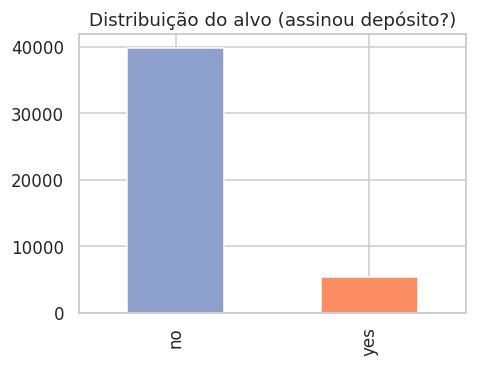

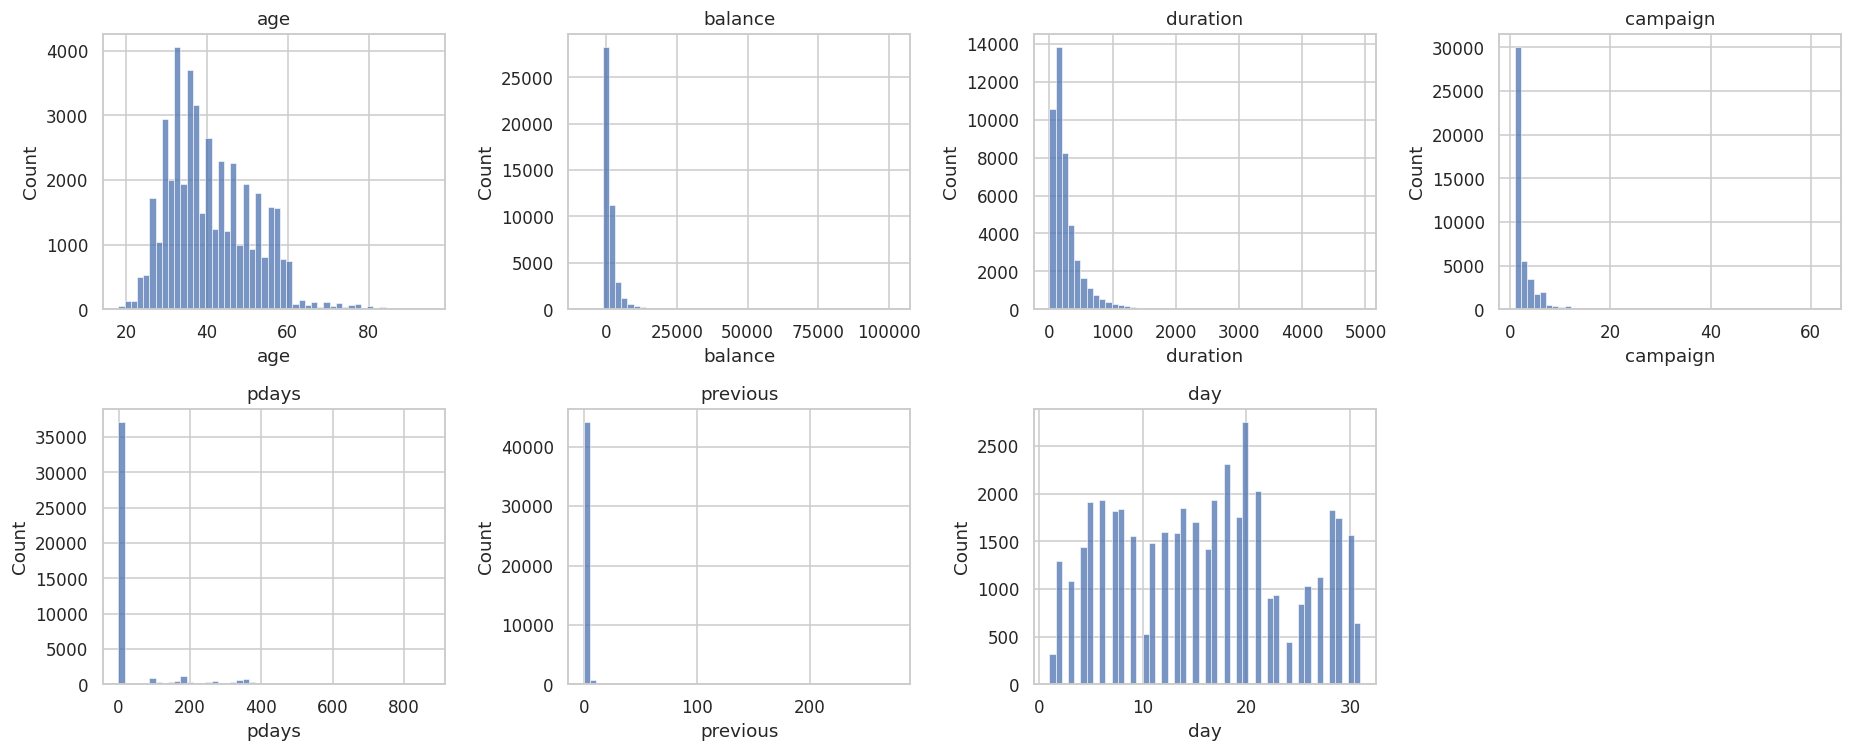

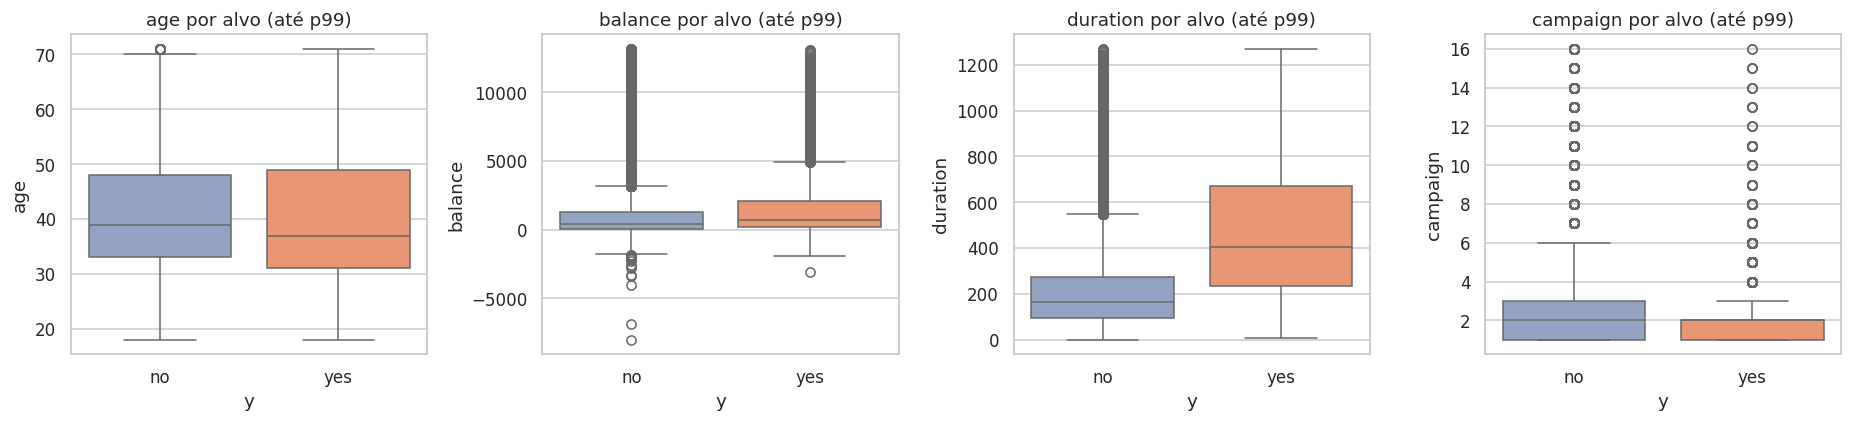

      age  balance  duration  campaign  previous
y                                               
no   39.0    417.0     164.0       2.0       0.0
yes  38.0    733.0     426.0       2.0       0.0


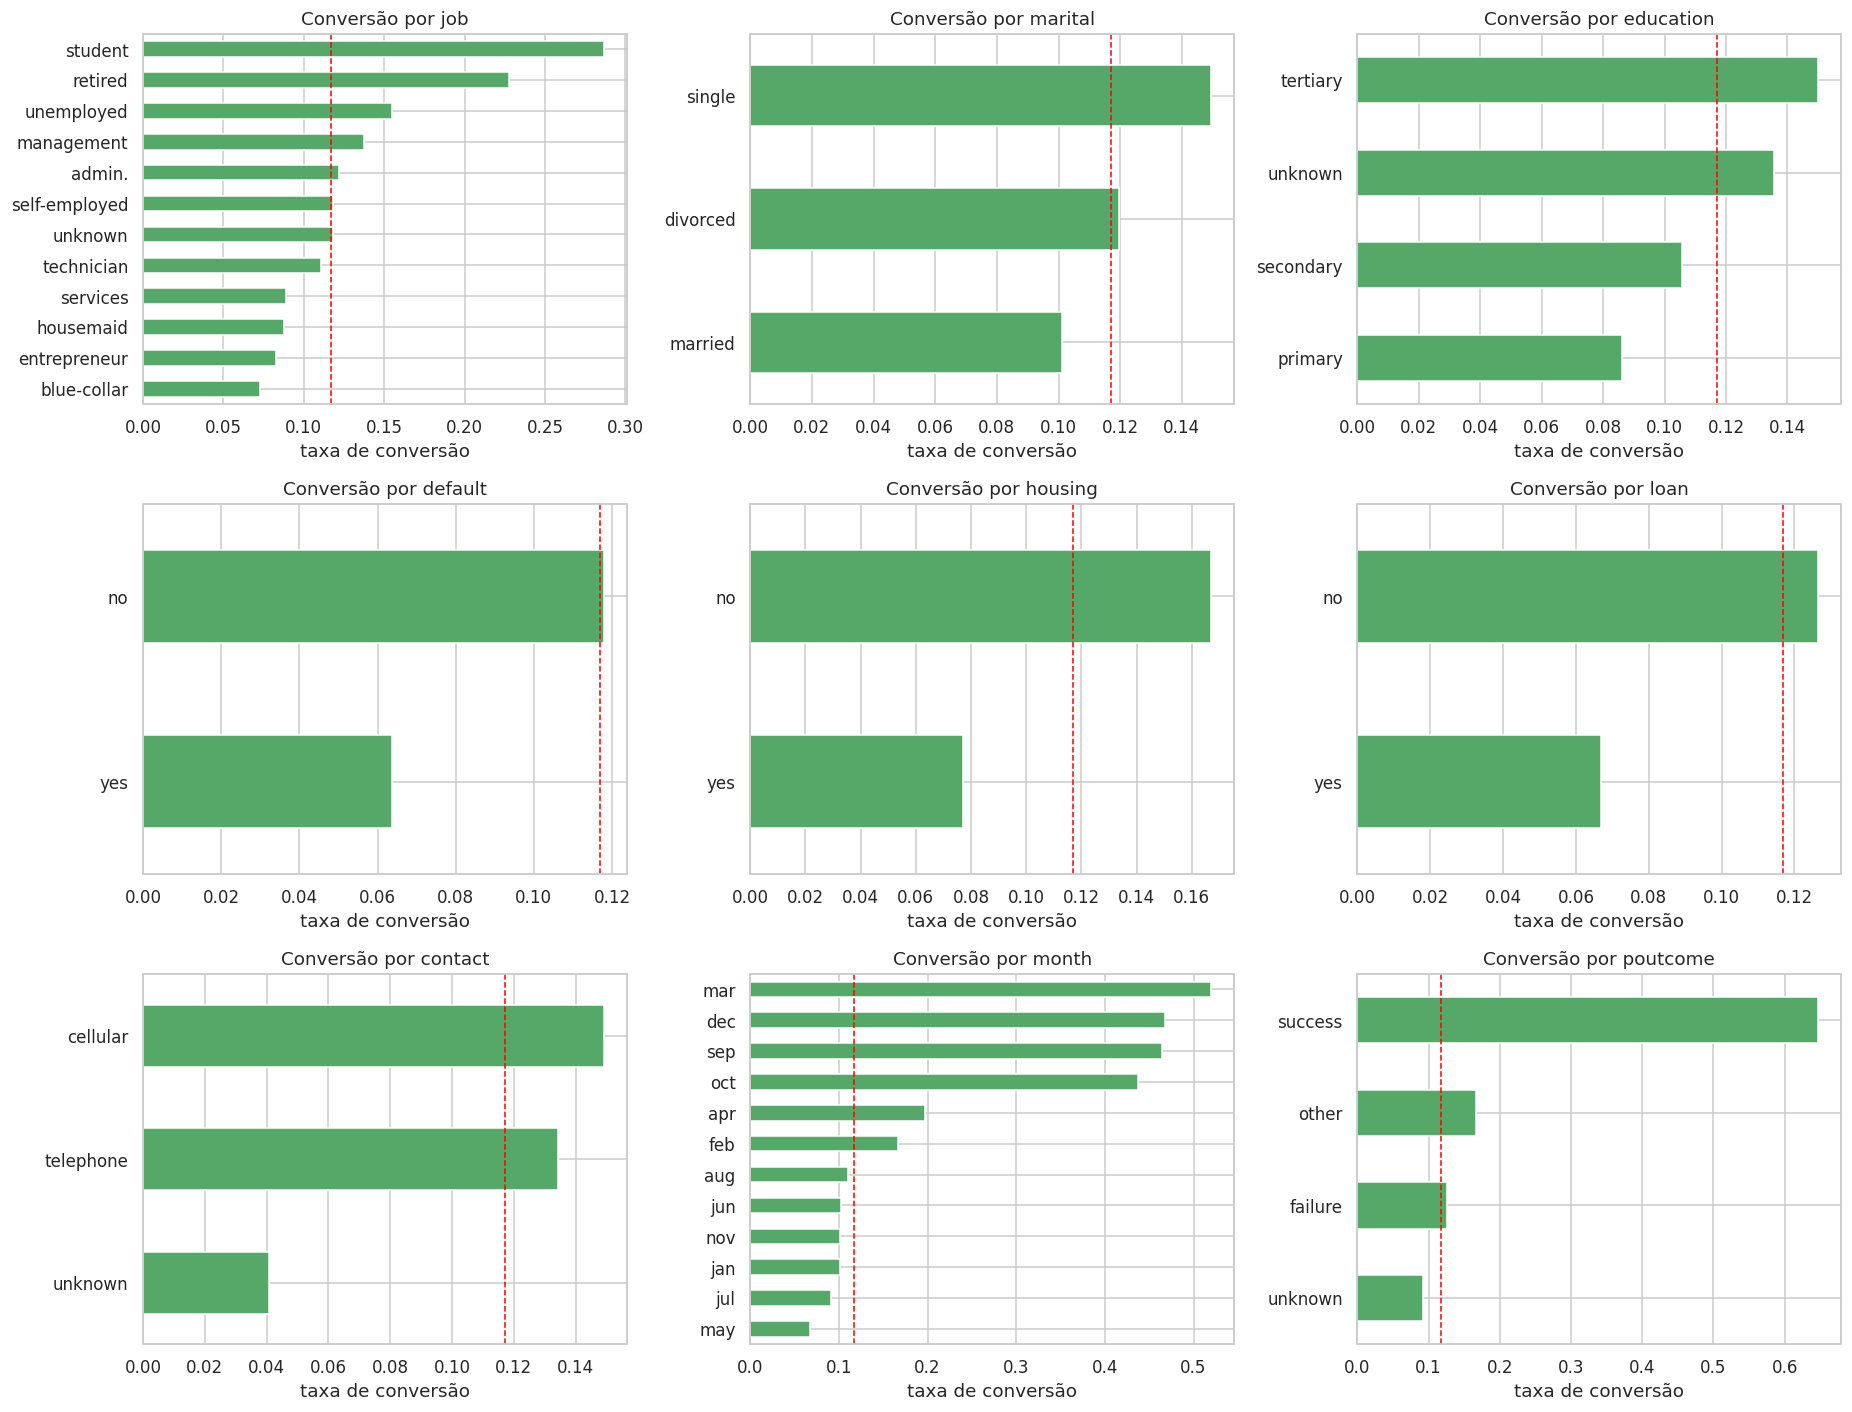

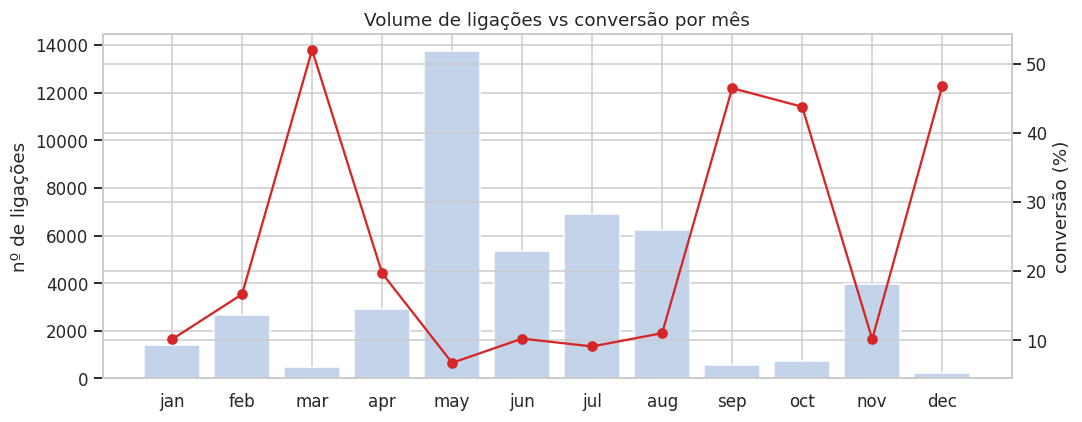

       ligacoes  conversao
month                     
jan        1403      0.101
feb        2649      0.166
mar         477      0.520
apr        2932      0.197
may       13766      0.067
jun        5341      0.102
jul        6895      0.091
aug        6247      0.110
sep         579      0.465
oct         738      0.438
nov        3970      0.102
dec         214      0.467


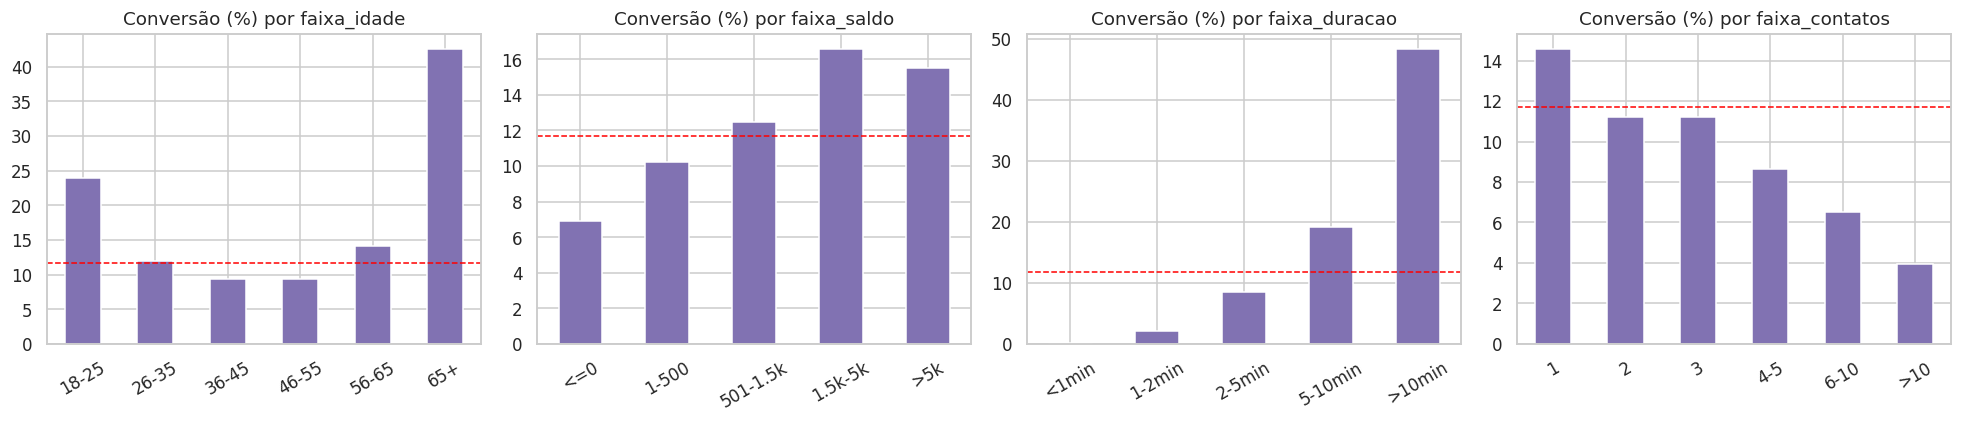

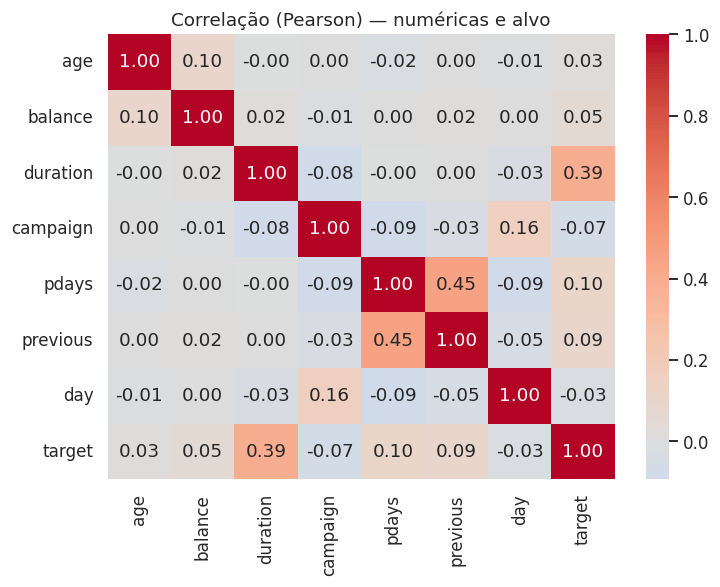

 variavel      chi2  p_valor  cramers_v
 poutcome 4391.5066      0.0     0.3117
    month 3061.8389      0.0     0.2602
  contact 1035.7142      0.0     0.1514
  housing  874.8224      0.0     0.1391
      job  836.1055      0.0     0.1360
education  238.9235      0.0     0.0727
     loan  209.6170      0.0     0.0681
  marital  196.4959      0.0     0.0659
  default   22.2022      0.0     0.0222

 variavel  mediana_sim  mediana_nao  p_valor  efeito_rank_biserial
duration        426.0        164.0   0.0000                0.6152
previous          0.0          0.0   0.0000                0.2046
   pdays         -1.0         -1.0   0.0000                0.1864
 balance        733.0        417.0   0.0000                0.1801
campaign          2.0          2.0   0.0000               -0.1447
     day         15.0         16.0   0.0000               -0.0530
     age         38.0         39.0   0.0628               -0.0157
                   cenario              modelo  AUC_cv  AUC_teste  PR_

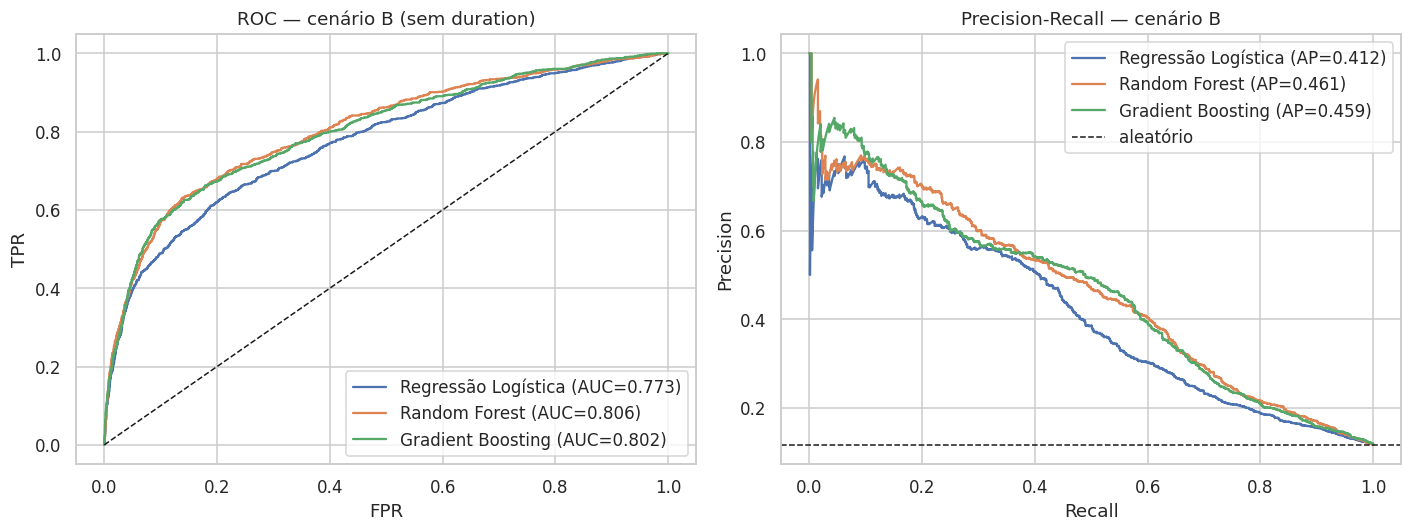

Melhor modelo (cenário B): Random Forest | limiar = 0.481
              precision    recall  f1-score   support

         não       0.94      0.90      0.92      7985
         sim       0.43      0.57      0.49      1058

    accuracy                           0.86      9043
   macro avg       0.69      0.74      0.71      9043
weighted avg       0.88      0.86      0.87      9043



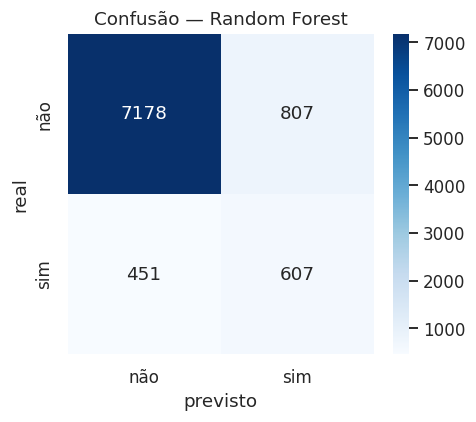

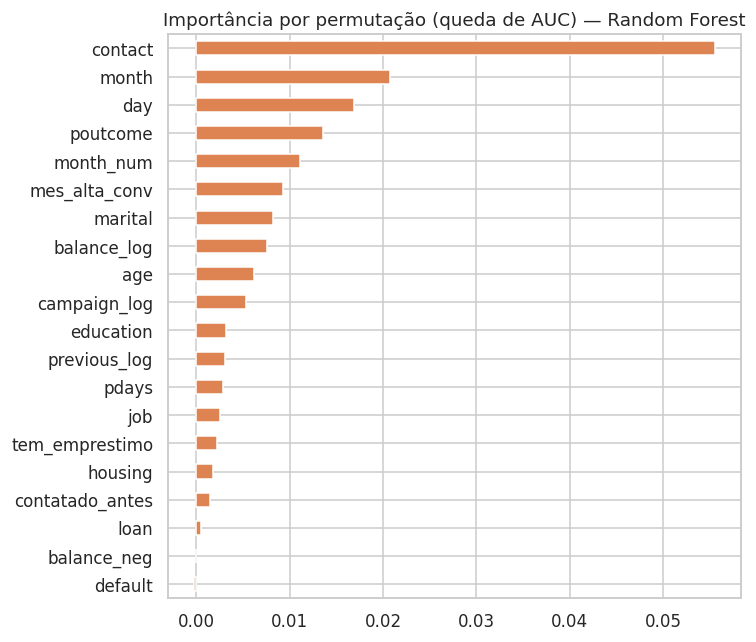

contact            0.0556
month              0.0208
day                0.0169
poutcome           0.0136
month_num          0.0111
mes_alta_conv      0.0092
marital            0.0082
balance_log        0.0076
age                0.0061
campaign_log       0.0053
education          0.0031
previous_log       0.0031
pdays              0.0029
job                0.0025
tem_emprestimo     0.0022
housing            0.0017
contatado_antes    0.0014
loan               0.0005
balance_neg       -0.0000
default           -0.0003
dtype: float64
       clientes  assinaturas  conversao   lift  ganho_acum_%
decil                                                       
1           905          461      0.509  4.354        43.573
2           904          209      0.231  1.976        63.327
3           904           89      0.098  0.841        71.739
4           904           61      0.067  0.577        77.505
5           905           72      0.080  0.680        84.310
6           904           50      0.05

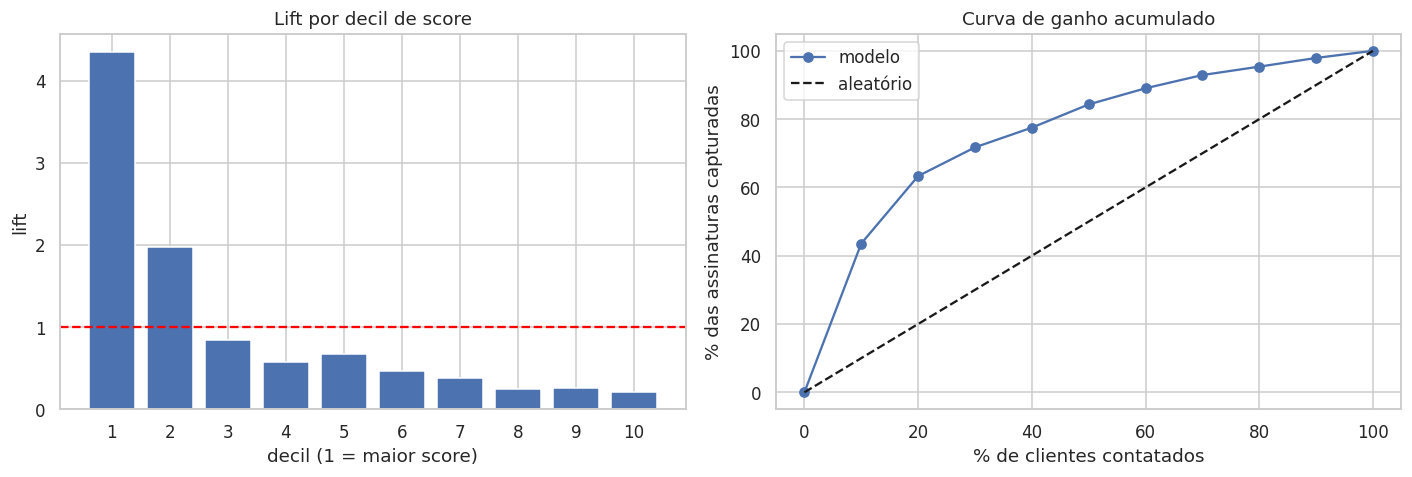


Simulação de lucro (hipóteses de custo/receita ajustáveis):
  %_contatados  ligacoes  assinaturas  conversao  recall  lucro_€
           10       904          460      0.509   0.435  50680.0
           20      1808          670      0.371   0.633  71360.0
           30      2712          759      0.280   0.717  77520.0
           40      3617          820      0.227   0.775  80315.0
           50      4521          892      0.197   0.843  84435.0
           70      6330          983      0.155   0.929  86310.0
          100      9043         1058      0.117   1.000  81745.0
RESUMO
- Conversão geral: 11.7% (base desbalanceada).
- Melhor modelo realista (sem duration): Random Forest | AUC=0.806 | PR-AUC=0.461
- Top 20% de clientes por score capturam 63% das assinaturas (lift decil 1 = 4.4x).
- Arquivos salvos em ./outputs_bank_marketing/


In [1]:
# %% [markdown]
# # Bank Marketing — Projeto completo de Análise de Dados e Machine Learning
# **Dataset:** UCI Bank Marketing (bank-full.csv, 45.211 clientes, 16 variáveis + alvo `y`)
# **Objetivo de negócio:** entender quem assina o depósito a prazo e priorizar ligações
# para aumentar a conversão reduzindo o custo de contato.
#
# Estrutura (CRISP-DM): 1) Carga e qualidade → 2) EDA → 3) Testes estatísticos →
# 4) Feature engineering → 5) Modelagem → 6) Avaliação → 7) Impacto de negócio.
#
# Como usar:
# - **Google Colab:** cole tudo em uma célula (ou célula por célula, os `# %%` separam).
#   Se não houver o CSV, o script baixa direto da UCI automaticamente.
# - **PyCharm/VS Code:** `pip install pandas numpy matplotlib seaborn scikit-learn scipy`
#   e rode. Os `# %%` funcionam como células no modo científico.

# %% 0. Imports e configuração
import io
import os
import urllib.request
import warnings
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, classification_report, confusion_matrix, f1_score,
    precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
OUT_DIR = "outputs_bank_marketing"          # gráficos e tabelas são salvos aqui
os.makedirs(OUT_DIR, exist_ok=True)


def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, name), bbox_inches="tight")
    plt.show()


# %% 1. Carga dos dados
# Ordem de busca: caminho local -> download da UCI -> upload manual (Colab).
UCI_URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
LOCAL_CANDIDATES = ["bank-full.csv", "bank/bank-full.csv", "data/bank-full.csv"]


def load_data():
    for p in LOCAL_CANDIDATES:
        if os.path.exists(p):
            print(f"Lendo arquivo local: {p}")
            return pd.read_csv(p, sep=";")
    try:
        print("Baixando da UCI...")
        raw = urllib.request.urlopen(UCI_URL, timeout=60).read()
        outer = zipfile.ZipFile(io.BytesIO(raw))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank.zip")))
        return pd.read_csv(inner.open("bank-full.csv"), sep=";")
    except Exception as e:
        print("Download falhou:", e)
    try:                                   # Colab
        from google.colab import files
        print("Faça upload do bank-full.csv")
        up = files.upload()
        return pd.read_csv(io.BytesIO(next(iter(up.values()))), sep=";")
    except ImportError:
        raise FileNotFoundError("Coloque bank-full.csv na pasta do script.")


df = load_data()
print(df.shape)
df.head()

# %% 2. Qualidade dos dados
print("Nulos:", int(df.isna().sum().sum()), "| Duplicados:", int(df.duplicated().sum()))
print(df.dtypes.value_counts())

# O dataset diz "sem missing", mas 'unknown' é um valor ausente disfarçado.
cat_cols_raw = df.select_dtypes("object").columns.drop("y")
unk = pd.DataFrame({
    "pct_unknown": [(df[c] == "unknown").mean() * 100 for c in cat_cols_raw]
}, index=cat_cols_raw).round(1).sort_values("pct_unknown", ascending=False)
print("\n% de 'unknown' por coluna:\n", unk[unk.pct_unknown > 0])

# pdays = -1 significa "nunca contatado antes" (não é um número real)
print("\n% nunca contatado antes (pdays=-1):", round((df.pdays == -1).mean() * 100, 1))
df.describe().T.round(1)

# %% 3. Variável-alvo
df["target"] = (df["y"] == "yes").astype(int)
conv = df["target"].mean()
print(f"Taxa de conversão geral: {conv:.2%}  (desbalanceado ~ 1:{(1-conv)/conv:.1f})")

fig, ax = plt.subplots(figsize=(4.5, 3.5))
df["y"].value_counts().plot.bar(ax=ax, color=["#8da0cb", "#fc8d62"])
ax.set_title("Distribuição do alvo (assinou depósito?)")
ax.set_xlabel("")
savefig("01_target.png")

# %% 4. EDA — variáveis numéricas
num_cols = ["age", "balance", "duration", "campaign", "pdays", "previous", "day"]
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=50, ax=ax, color="#4c72b0")
    ax.set_title(c)
axes.ravel()[-1].axis("off")
savefig("02_numericas_dist.png")

# Boxplot das principais numéricas por alvo (com clip em p99 para legibilidade)
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, c in zip(axes, ["age", "balance", "duration", "campaign"]):
    d = df[df[c] <= df[c].quantile(0.99)]
    sns.boxplot(data=d, x="y", y=c, ax=ax, palette=["#8da0cb", "#fc8d62"])
    ax.set_title(f"{c} por alvo (até p99)")
savefig("03_numericas_vs_alvo.png")

print(df.groupby("y")[["age", "balance", "duration", "campaign", "previous"]].median())

# %% 5. EDA — taxa de conversão por categoria
cat_cols = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "poutcome"]
fig, axes = plt.subplots(3, 3, figsize=(17, 13))
for ax, c in zip(axes.ravel(), cat_cols):
    t = df.groupby(c)["target"].mean().sort_values()
    t.plot.barh(ax=ax, color="#55a868")
    ax.axvline(conv, color="red", ls="--", lw=1)
    ax.set_title(f"Conversão por {c}")
    ax.set_xlabel("taxa de conversão")
    ax.set_ylabel("")
savefig("04_conversao_por_categoria.png")

# Sazonalidade: volume de ligações x conversão por mês
order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
m = df.groupby("month").agg(ligacoes=("target", "size"), conversao=("target", "mean")).reindex(order)
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(m.index, m.ligacoes, color="#c3d3ea")
ax1.set_ylabel("nº de ligações")
ax2 = ax1.twinx()
ax2.plot(m.index, m.conversao * 100, color="#d62728", marker="o")
ax2.set_ylabel("conversão (%)")
ax1.set_title("Volume de ligações vs conversão por mês")
savefig("05_sazonalidade.png")
print(m.round(3))

# %% 6. Segmentos: idade, saldo, duração, nº de contatos
df["faixa_idade"] = pd.cut(df.age, [17, 25, 35, 45, 55, 65, 100],
                           labels=["18-25", "26-35", "36-45", "46-55", "56-65", "65+"])
df["faixa_saldo"] = pd.cut(df.balance, [-np.inf, 0, 500, 1500, 5000, np.inf],
                           labels=["<=0", "1-500", "501-1.5k", "1.5k-5k", ">5k"])
df["faixa_duracao"] = pd.cut(df.duration, [-1, 60, 120, 300, 600, np.inf],
                             labels=["<1min", "1-2min", "2-5min", "5-10min", ">10min"])
df["faixa_contatos"] = pd.cut(df.campaign, [0, 1, 2, 3, 5, 10, np.inf],
                              labels=["1", "2", "3", "4-5", "6-10", ">10"])
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ["faixa_idade", "faixa_saldo", "faixa_duracao", "faixa_contatos"]):
    g = df.groupby(c)["target"].mean() * 100
    g.plot.bar(ax=ax, color="#8172b2", rot=30)
    ax.axhline(conv * 100, color="red", ls="--", lw=1)
    ax.set_title(f"Conversão (%) por {c}")
    ax.set_xlabel("")
savefig("06_conversao_faixas.png")

# %% 7. Correlação
corr = df[num_cols + ["target"]].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação (Pearson) — numéricas e alvo")
savefig("07_correlacao.png")

# %% 8. Testes estatísticos
# 8.1 Qui-quadrado + V de Cramér para categóricas vs alvo
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    v = np.sqrt((chi2 / n) / (min(ct.shape) - 1))
    return chi2, p, v


rows = []
for c in cat_cols:
    chi2, p, v = cramers_v(df[c], df["target"])
    rows.append((c, chi2, p, v))
chi_tbl = pd.DataFrame(rows, columns=["variavel", "chi2", "p_valor", "cramers_v"]) \
    .sort_values("cramers_v", ascending=False).round(4)
print(chi_tbl.to_string(index=False))

# 8.2 Mann-Whitney para numéricas (não assumem normalidade) + tamanho de efeito
rows = []
for c in num_cols:
    a, b = df.loc[df.target == 1, c], df.loc[df.target == 0, c]
    u, p = stats.mannwhitneyu(a, b)
    r = 1 - 2 * u / (len(a) * len(b))      # rank-biserial (sinal indica direção)
    rows.append((c, a.median(), b.median(), p, -r))
mw_tbl = pd.DataFrame(rows, columns=["variavel", "mediana_sim", "mediana_nao",
                                     "p_valor", "efeito_rank_biserial"]).round(4) \
    .sort_values("efeito_rank_biserial", key=abs, ascending=False)
print("\n", mw_tbl.to_string(index=False))

chi_tbl.to_csv(os.path.join(OUT_DIR, "teste_qui_quadrado.csv"), index=False)
mw_tbl.to_csv(os.path.join(OUT_DIR, "teste_mann_whitney.csv"), index=False)

# %% 9. Feature engineering
def make_features(d):
    x = d.copy()
    x["contatado_antes"] = (x["pdays"] != -1).astype(int)
    x["pdays"] = x["pdays"].replace(-1, np.nan)             # -1 não é número real
    x["balance_neg"] = (x["balance"] < 0).astype(int)
    x["balance_log"] = np.sign(x["balance"]) * np.log1p(x["balance"].abs())
    x["campaign_log"] = np.log1p(x["campaign"])
    x["previous_log"] = np.log1p(x["previous"])
    x["tem_emprestimo"] = ((x["housing"] == "yes") | (x["loan"] == "yes")).astype(int)
    month_map = {m: i + 1 for i, m in enumerate(order)}
    x["month_num"] = x["month"].map(month_map)
    x["mes_alta_conv"] = x["month"].isin(["mar", "sep", "oct", "dec"]).astype(int)
    return x


df_fe = make_features(df)

# %% 10. Pipeline de modelagem
# IMPORTANTE (data leakage): 'duration' só é conhecida DEPOIS da ligação. A própria
# documentação da UCI recomenda removê-la para um modelo preditivo realista.
# Por isso treinamos dois cenários:
#   A) COM duration  -> benchmark (teto de desempenho, não utilizável antes da ligação)
#   B) SEM duration  -> modelo realista para priorizar a lista de ligações
base_num = ["age", "balance_log", "day", "campaign_log", "pdays", "previous_log",
            "contatado_antes", "balance_neg", "tem_emprestimo", "month_num", "mes_alta_conv"]
base_cat = ["job", "marital", "education", "default", "housing", "loan", "contact",
            "month", "poutcome"]

X_train_idx, X_test_idx = train_test_split(
    df_fe.index, test_size=0.2, stratify=df_fe["target"], random_state=RANDOM_STATE)
y = df_fe["target"]


def build_preprocessor(num, cat, scale):
    from sklearn.impute import SimpleImputer
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=False))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cat),
    ])


def get_models(num, cat):
    return {
        "Regressão Logística": Pipeline([
            ("prep", build_preprocessor(num, cat, scale=True)),
            ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        "Random Forest": Pipeline([
            ("prep", build_preprocessor(num, cat, scale=False)),
            ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1,
                                           class_weight="balanced_subsample",
                                           random_state=RANDOM_STATE))]),
        "Gradient Boosting": Pipeline([
            ("prep", build_preprocessor(num, cat, scale=False)),
            ("clf", HistGradientBoostingClassifier(learning_rate=0.08, max_iter=300,
                                                   max_leaf_nodes=15, l2_regularization=1.0,
                                                   early_stopping=True,
                                                   random_state=RANDOM_STATE))]),
    }


def run_scenario(name, num, cat):
    Xtr, Xte = df_fe.loc[X_train_idx, num + cat], df_fe.loc[X_test_idx, num + cat]
    ytr, yte = y.loc[X_train_idx], y.loc[X_test_idx]
    cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
    res, fitted, probas = [], {}, {}
    for mname, pipe in get_models(num, cat).items():
        cv_auc = cross_val_score(pipe, Xtr, ytr, cv=cv, scoring="roc_auc", n_jobs=-1).mean()
        pipe.fit(Xtr, ytr)
        p = pipe.predict_proba(Xte)[:, 1]
        # limiar que maximiza F1 (calculado no treino via CV seria ideal; aqui no teste p/ ilustrar)
        prec, rec, thr = precision_recall_curve(yte, p)
        f1s = 2 * prec * rec / (prec + rec + 1e-9)
        best = thr[np.argmax(f1s[:-1])]
        res.append({"cenario": name, "modelo": mname, "AUC_cv": cv_auc,
                    "AUC_teste": roc_auc_score(yte, p),
                    "PR_AUC": average_precision_score(yte, p),
                    "F1@melhor_limiar": f1_score(yte, p >= best), "limiar": best})
        fitted[mname], probas[mname] = pipe, p
    return pd.DataFrame(res), fitted, probas, Xte, yte


# %% 11. Treino e comparação
res_A, fit_A, prob_A, Xte_A, yte = run_scenario("A) com duration", base_num + ["duration"], base_cat)
res_B, fit_B, prob_B, Xte_B, _ = run_scenario("B) sem duration (realista)", base_num, base_cat)
results = pd.concat([res_A, res_B]).round(4)
print(results.to_string(index=False))
results.to_csv(os.path.join(OUT_DIR, "resultados_modelos.csv"), index=False)

# %% 12. Curvas ROC e Precision-Recall
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for mname, p in prob_B.items():
    fpr, tpr, _ = roc_curve(yte, p)
    axes[0].plot(fpr, tpr, label=f"{mname} (AUC={roc_auc_score(yte, p):.3f})")
    pr, rc, _ = precision_recall_curve(yte, p)
    axes[1].plot(rc, pr, label=f"{mname} (AP={average_precision_score(yte, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC — cenário B (sem duration)", xlabel="FPR", ylabel="TPR")
axes[1].axhline(yte.mean(), color="k", ls="--", lw=1, label="aleatório")
axes[1].set(title="Precision-Recall — cenário B", xlabel="Recall", ylabel="Precision")
axes[0].legend(); axes[1].legend()
savefig("08_roc_pr.png")

# %% 13. Melhor modelo realista: matriz de confusão e relatório
best_name = res_B.sort_values("AUC_teste", ascending=False).iloc[0]["modelo"]
best_thr = res_B.set_index("modelo").loc[best_name, "limiar"]
p_best = prob_B[best_name]
pred = (p_best >= best_thr).astype(int)
print(f"Melhor modelo (cenário B): {best_name} | limiar = {best_thr:.3f}")
print(classification_report(yte, pred, target_names=["não", "sim"]))
cm = confusion_matrix(yte, pred)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["não", "sim"],
            yticklabels=["não", "sim"])
plt.xlabel("previsto"); plt.ylabel("real"); plt.title(f"Confusão — {best_name}")
savefig("09_confusao.png")

# %% 14. Importância das variáveis (permutação, no teste)
pipe = fit_B[best_name]
imp = permutation_importance(pipe, Xte_B, yte, scoring="roc_auc", n_repeats=8,
                             random_state=RANDOM_STATE, n_jobs=-1)
imp_df = pd.Series(imp.importances_mean, index=Xte_B.columns).sort_values()
plt.figure(figsize=(7, 6))
imp_df.plot.barh(color="#dd8452")
plt.title(f"Importância por permutação (queda de AUC) — {best_name}")
savefig("10_importancia.png")
print(imp_df.sort_values(ascending=False).round(4))

# %% 15. Impacto de negócio: ganho acumulado (gains) e lift por decil
eval_df = pd.DataFrame({"y": yte.values, "p": p_best}).sort_values("p", ascending=False)
eval_df["decil"] = pd.qcut(np.arange(len(eval_df)), 10, labels=range(1, 11))
dec = eval_df.groupby("decil").agg(clientes=("y", "size"), assinaturas=("y", "sum"),
                                    conversao=("y", "mean"))
dec["lift"] = dec["conversao"] / eval_df["y"].mean()
dec["ganho_acum_%"] = dec["assinaturas"].cumsum() / dec["assinaturas"].sum() * 100
print(dec.round(3))
dec.round(4).to_csv(os.path.join(OUT_DIR, "lift_por_decil.csv"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(dec.index.astype(str), dec["lift"], color="#4c72b0")
axes[0].axhline(1, color="red", ls="--")
axes[0].set(title="Lift por decil de score", xlabel="decil (1 = maior score)", ylabel="lift")
x = np.r_[0, np.arange(1, 11) * 10]
axes[1].plot(x, np.r_[0, dec["ganho_acum_%"]], marker="o", label="modelo")
axes[1].plot([0, 100], [0, 100], "k--", label="aleatório")
axes[1].set(title="Curva de ganho acumulado", xlabel="% de clientes contatados",
            ylabel="% das assinaturas capturadas")
axes[1].legend()
savefig("11_lift_ganho.png")

# Simulação simples de ROI — AJUSTE os parâmetros à realidade do banco
CUSTO_LIGACAO = 5.0      # € por contato (hipótese)
RECEITA_ASSINATURA = 120.0   # € de margem por depósito (hipótese)
n = len(eval_df)
rows = []
for pct in [10, 20, 30, 40, 50, 70, 100]:
    top = eval_df.head(int(n * pct / 100))
    lucro = top["y"].sum() * RECEITA_ASSINATURA - len(top) * CUSTO_LIGACAO
    rows.append((pct, len(top), top["y"].sum(), top["y"].mean(),
                 top["y"].sum() / eval_df["y"].sum(), lucro))
roi = pd.DataFrame(rows, columns=["%_contatados", "ligacoes", "assinaturas",
                                  "conversao", "recall", "lucro_€"]).round(3)
print("\nSimulação de lucro (hipóteses de custo/receita ajustáveis):\n", roi.to_string(index=False))
roi.to_csv(os.path.join(OUT_DIR, "simulacao_roi.csv"), index=False)

# %% 16. Conclusões automáticas
print("=" * 70)
print("RESUMO")
print("=" * 70)
print(f"- Conversão geral: {conv:.1%} (base desbalanceada).")
print(f"- Melhor modelo realista (sem duration): {best_name} | "
      f"AUC={roc_auc_score(yte, p_best):.3f} | PR-AUC={average_precision_score(yte, p_best):.3f}")
print(f"- Top 20% de clientes por score capturam {dec['ganho_acum_%'].iloc[1]:.0f}% das assinaturas "
      f"(lift decil 1 = {dec['lift'].iloc[0]:.1f}x).")
print(f"- Arquivos salvos em ./{OUT_DIR}/")